# NLP Group Assignment 2: English to Hindi translation, with and without attention

Code lives in four small files next to this notebook: `data.py` (Part 1), `models.py` (Parts 2 and 4), `train.py` (training) and `analyze.py` (analysis and plots). Both models were trained with `python train.py baseline 8 6` and `python train.py attention 8 6` (run in parallel, 8 epochs each, 6 CPU threads each). This notebook loads the saved models and does the analysis.

## Part 1: Data preparation

In [1]:
import warnings; warnings.filterwarnings("ignore")
from data import *
from analyze import *
import pandas as pd

data = prepare()

training pairs used     : 50000
dev / test pairs        : 430 / 1723
English vocab size      : 10000
Hindi vocab size        : 10000
max English length      : 27 (with <SOS> <EOS>)
max Hindi length        : 27 (with <SOS> <EOS>)
unknown word rate       : English 7.2%, Hindi 9.8%


Cleaning rules: a pair is dropped if one side is empty, either side is longer than 25 tokens, one side is more than 3 times longer than the other, or the Hindi side has no Devanagari letters. English is lowercased and invisible joiner characters are removed. 50,000 pairs are kept from a random 200,000 of the 1.6M raw pairs. Each vocabulary keeps the 10,000 most common words and everything else becomes `<UNK>` (7.2% of English and 9.8% of Hindi training words). Dev and test sentences may be up to 30 tokens so the 16+ group is not empty.

In [2]:
en, hi = data["train"][1]
print("English:", ["<SOS>"] + en + ["<EOS>"])
print("Hindi  :", ["<SOS>"] + hi + ["<EOS>"])
print("English ids:", encode(en, data["en_stoi"]))
print("Hindi ids  :", encode(hi, data["hi_stoi"]))
padded, lengths = pad([encode(e, data["en_stoi"]) for e, _ in data["train"][:4]])
print("a padded batch of 4 sentences (0 = <PAD>):")
print(padded)
print("real lengths:", lengths)

English: ['<SOS>', 'the', 'richness', 'of', 'our', 'culture', 'and', 'its', 'living', 'symbols', 'is', 'unique', '.', '<EOS>']
Hindi  : ['<SOS>', 'हमारी', 'संस्कृति', 'और', 'इसके', 'जीवित', 'प्रतीकों', 'की', 'समृद्धि', 'अद्वितीय', 'है', '।', '<EOS>']
English ids: [1, 5, 3, 6, 67, 644, 9, 85, 696, 3109, 12, 1339, 4, 2]
Hindi ids  : [1, 221, 917, 10, 119, 1322, 3, 8, 2093, 5563, 6, 4, 2]
a padded batch of 4 sentences (0 = <PAD>):
[[   1    3    2    0    0    0    0    0    0    0    0    0    0    0]
 [   1    5    3    6   67  644    9   85  696 3109   12 1339    4    2]
 [   1  645 4503  288 3110    2    0    0    0    0    0    0    0    0]
 [   1  481    2    0    0    0    0    0    0    0    0    0    0    0]]
real lengths: [ 3 14  6  3]


## Parts 2 and 4: the two models

In [3]:
models = {name: load_model(name, data) for name in ["baseline", "attention"]}
for name, m in models.items():
    print(name, "->", sum(p.numel() for p in m.parameters()), "parameters")
print()
print(models["attention"].decoder.attn)

baseline -> 5920528 parameters
attention -> 6314256 parameters

Attention(
  (W_h): Linear(in_features=256, out_features=256, bias=False)
  (W_s): Linear(in_features=256, out_features=256, bias=True)
  (v): Linear(in_features=256, out_features=1, bias=False)
)


In [4]:
# one sentence through the attention model: each row of alpha is one generated word and sums to 1
sent = [data["test"][3]]
src, src_len, _ = to_tensors(sent, data)
words, alpha = models["attention"].translate(src, src_len)
print("English:", sent[0][0])
print("alpha shape (generated words x source words):", tuple(alpha[0].shape))
print("each row sums to:", alpha[0].sum(dim=1)[:5])

English: ['the', 'american', 'civil', 'liberties', 'union', 'is', 'deeply', 'concerned', ',', 'too', ',', 'raising', 'a', 'variety', 'of', 'privacy', 'issues', '.']
alpha shape (generated words x source words): (22, 20)
each row sums to: 

tensor([1.0000, 1.0000, 1.0000, 1.0000, 1.0000])


How the attention works (class `Attention` in `models.py`): before generating each Hindi word, every English hidden state h_i is scored against the decoder's previous state s with `v . tanh(W_s s + W_h h_i)`. A softmax turns the scores into weights alpha (padding is masked out) and the weighted sum of the h_i is the context vector, which goes into the decoder LSTM together with the previous Hindi word. The baseline is the same model with this block switched off, so it only sees the final encoder state. Both models use the same sizes, optimizer, learning rate, batch size, dropout, epochs and seed.

## Part 5: training curves (Model A = baseline, Model B = attention)

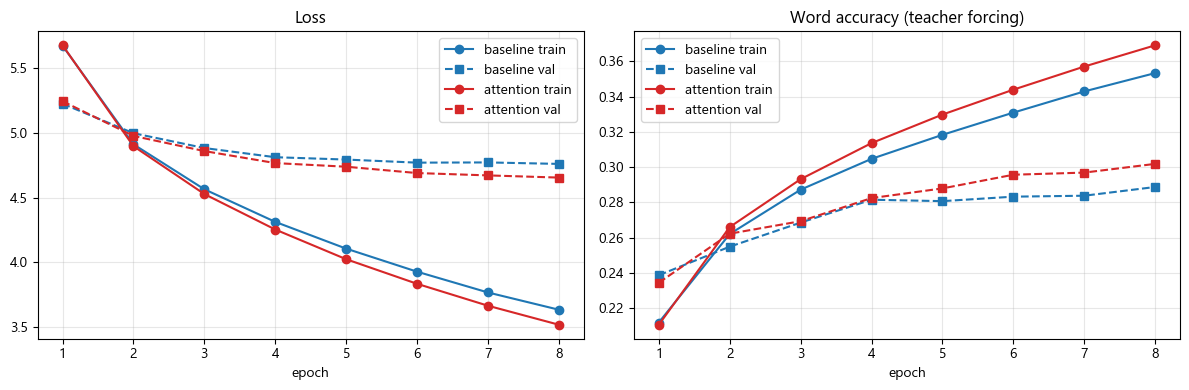

,model,best epoch,train loss,val loss,train acc,val acc,sec/epoch
0,baseline,8,3.636,4.760,0.353,0.289,409.343
1,attention,8,3.520,4.654,0.369,0.302,482.127


In [5]:
histories = {name: load_history(name) for name in ["baseline", "attention"]}
plot_curves(histories, "results/curves.png")
rows = []
for name, h in histories.items():
    best = int(np.argmin(h["val_loss"]))
    rows.append({"model": name, "best epoch": best + 1, "train loss": h["train_loss"][best], "val loss": h["val_loss"][best],
                 "train acc": h["train_acc"][best], "val acc": h["val_acc"][best], "sec/epoch": np.mean(h["epoch_time"])})
pd.DataFrame(rows).round(3)

Both models trained for 8 epochs with identical settings and the best epoch by validation loss was kept (the last one for both, so they were still improving slowly). Training loss ends at 3.64 (baseline) and 3.52 (attention). Validation loss is 4.760 vs 4.654 and validation word accuracy 0.289 vs 0.302. Both overfit (training loss is about 1.1 below validation loss) and attention generalises a bit better. Time per epoch was 409 s vs 482 s, but the two models trained at the same time on one CPU, so these include some waiting.

## Translating the test set

In [6]:
test = data["test"]
refs = [h for _, h in test]
hyps, alphas = {}, {}
for name, m in models.items():
    hyps[name], alphas[name] = translate_all(m, test, data)

hyps_unk = {name: translate_all(m, test, data, ban_unk=False)[0] for name, m in models.items()}

rows = []
for name, m in models.items():
    loss, acc = run_epoch(m, test, data)
    rows.append({"model": name, "BLEU (no <UNK> allowed)": bleu(hyps[name], refs), "BLEU (<UNK> allowed)": bleu(hyps_unk[name], refs),
                 "test loss": loss, "word accuracy": acc})
print(len(test), "test sentences")
pd.DataFrame(rows).round(3)

1723 test sentences


,model,BLEU (no <UNK> allowed),BLEU (<UNK> allowed),test loss,word accuracy
0,baseline,0.602,0.512,4.713,0.281
1,attention,0.918,0.612,4.621,0.293


The decoder is greedy (most likely word at every step). If `<UNK>` is allowed, 57% (baseline) and 67% (attention) of the generated words are `<UNK>`, because it is the most common single token in training, and that leaves little to analyse. So `<UNK>` is not allowed at decoding time (the table shows BLEU both ways). BLEU is still below 1 for both models on a 0 to 100 scale: with 50,000 sentence pairs and a word level vocabulary the models learn common Hindi phrases and the beginning of sentences, not full translation, so the comparison below is about small differences. That is why I also use word overlap per sentence and a paired comparison in Part 9.

An earlier run with 30,000 pairs and 6 epochs gave BLEU 0.41 (baseline) and 0.56 (attention) and word overlap 0.173 vs 0.183. More data and epochs raised both models (BLEU 0.60 and 0.92, overlap 0.187 and 0.205) and made the gap between them larger. That run is kept in `results_run1_30k/`.

In [7]:
rows = []
for i in [i for i, (e, _) in enumerate(test) if 6 <= len(e) <= 12][:10]:
    rows.append({"English": " ".join(test[i][0]), "Reference": " ".join(refs[i]),
                 "Baseline": " ".join(hyps["baseline"][i]), "Attention": " ".join(hyps["attention"][i])})
pd.set_option("display.max_colwidth", 80)
pd.DataFrame(rows)

,English,Reference,Baseline,Attention
0,a black box in your car ?,आपकी कार में ब्लैक बॉक्स ?,एक बार फिर से एक बार फिर कोशिश करें ?,अपने अगले बाप में क्या हमारे पास एक ही ?
1,the tea party is aghast .,चाय पार्टी भौचक्की है ।,यह विज्ञप्ति 1230 पर कार्य करती है ।,तीसरा - धीरे धीरे धीरे धीरे धीरे धीरे - धीरे - धीरे - धीरे - नायिका किया जात...
2,this really is a must for our nation .,यह हमारे देश के लिए वास्तव में अनिवार्य वस्तु है ।,यह हमारे देश के लिए हमारी है ।,यह हमारा देश है कि हमारे देश के लिए एक बहुत ही है ।
3,the technology is there to do it .,ऐसा करने के लिए प्रौद्योगिकी है ।,दोनों पक्षों के लिए यह है ।,हमारी ओर यह है कि यह है ।
4,cars get many more miles to the gallon .,अब एक गैलन गैस में कार पहले से अधिक मील चलती है ।,कुछ समय बाद से अधिक ही अधिक थी ।,उसे अधिक आयु के साथ ही अधिक गम्भीर होती है ।
5,wonks call it a mileage - based user fee .,वॉन्क्स इसे माइलेज - आधारित उपयोगकर्ता शुल्क कहते हैं ।,यह विज्ञप्ति 1230 बजे जारी की गई थी ।,यह एक ही एक प्रकार की तरह से एक ही समय -
6,people are paying more directly into what they are getting .,"लोग जो चीज प्राप्त कर रहे हैं , उसके लिए अधिक प्रत्यक्ष रूप से भुगतान कर रहे...",वह लोग जो लोग ईमान लाए और उनके लिए बहुत ही बुरा ठिकाना है,ये लोग लोग तो वे लोग हैं ।
7,several states and cities are nonetheless moving ahead on their own .,फिर भी बहुत से राज्य और शहर खुद - ब - खुद इस दिशा में आगे बढ़ रहे हैं ।,इन दोनों देशों ने अपनी जीवन और अपनी उपलब्धियों पर ध्यान दिया ।,हमारे दोनों देशों और उनके पास बहुत ही चेतना पर भी रहते हैं ।
8,nevada has already completed a pilot .,नेवाडा ने पहले ही प्रारंभिक परीक्षण पूर्ण कर लिया है ।,एक आयोजक निश्चित रूप से निर्मित किया जाता है ।,यह एक नई घटना को भी किया गया है ।
9,new york city is looking into one .,न्यू यॉर्क शहर भी इस दिशा में आगे बढ़ रहा है ।,नई प्रौद्योगिकियों में एक नई संख्या ।,नई दिल्ली में एक ही बहुत ही है ।


In [8]:
all_rows = [{"English": " ".join(e), "Reference": " ".join(h), "Baseline": " ".join(hyps["baseline"][i]), "Attention": " ".join(hyps["attention"][i])}
            for i, (e, h) in enumerate(test)]
pd.DataFrame(all_rows).to_csv("results/test_translations.csv", index=False, encoding="utf-8-sig")
print("saved", len(all_rows), "translations to results/test_translations.csv")

saved 1723 translations to results/test_translations.csv


## Part 3: the limit of the baseline (short vs long sentences)

In [9]:
rows = length_table({"baseline": models["baseline"]}, test, data, hyps)
print(pd.DataFrame(rows).round(3).to_string(index=False))
print()
for name, lo, hi in [("short (1-10 tokens)", 1, 10), ("long (16+ tokens)", 16, 999)]:
    idx = [i for i, (e, _) in enumerate(test) if lo <= len(e) <= hi]
    first, last = first_last_recall([hyps["baseline"][i] for i in idx], [refs[i] for i in idx])
    print(f"baseline, {name}: reference words found in the translation  first third {first:.2f}   last third {last:.2f}")

bucket    n  baseline_bleu  baseline_acc
   1-5   10          1.971         0.440
  6-10  256          1.252         0.343
 11-15  455          0.559         0.296
   16+ 1002          0.488         0.267

baseline, short (1-10 tokens): reference words found in the translation  first third 0.14   last third 0.33
baseline, long (16+ tokens): reference words found in the translation  first third 0.18   last third 0.25


**Long sentences are harder for the baseline.** Word accuracy goes 0.44 (1-5 tokens), 0.34, 0.30, 0.27 (16+) and BLEU goes 1.97, 1.25, 0.56, 0.49, falling at every step. The reason is that the whole English sentence has to be squeezed into one 256 number vector (the last hidden state) before decoding starts, and a longer sentence has more to fit into the same space. The 1-5 group has only 10 sentences, so it is not reliable.

**Are early words lost?** The numbers do not show it clearly. In short sentences 14% of the reference words from the first third appear in the translation against 33% from the last third, and in long ones 18% against 25%. But the end of a Hindi sentence is mostly है and ।, which the model always produces, so this does not prove that early words are forgotten. It only fits that idea.

## Part 6: what the attention model looks at

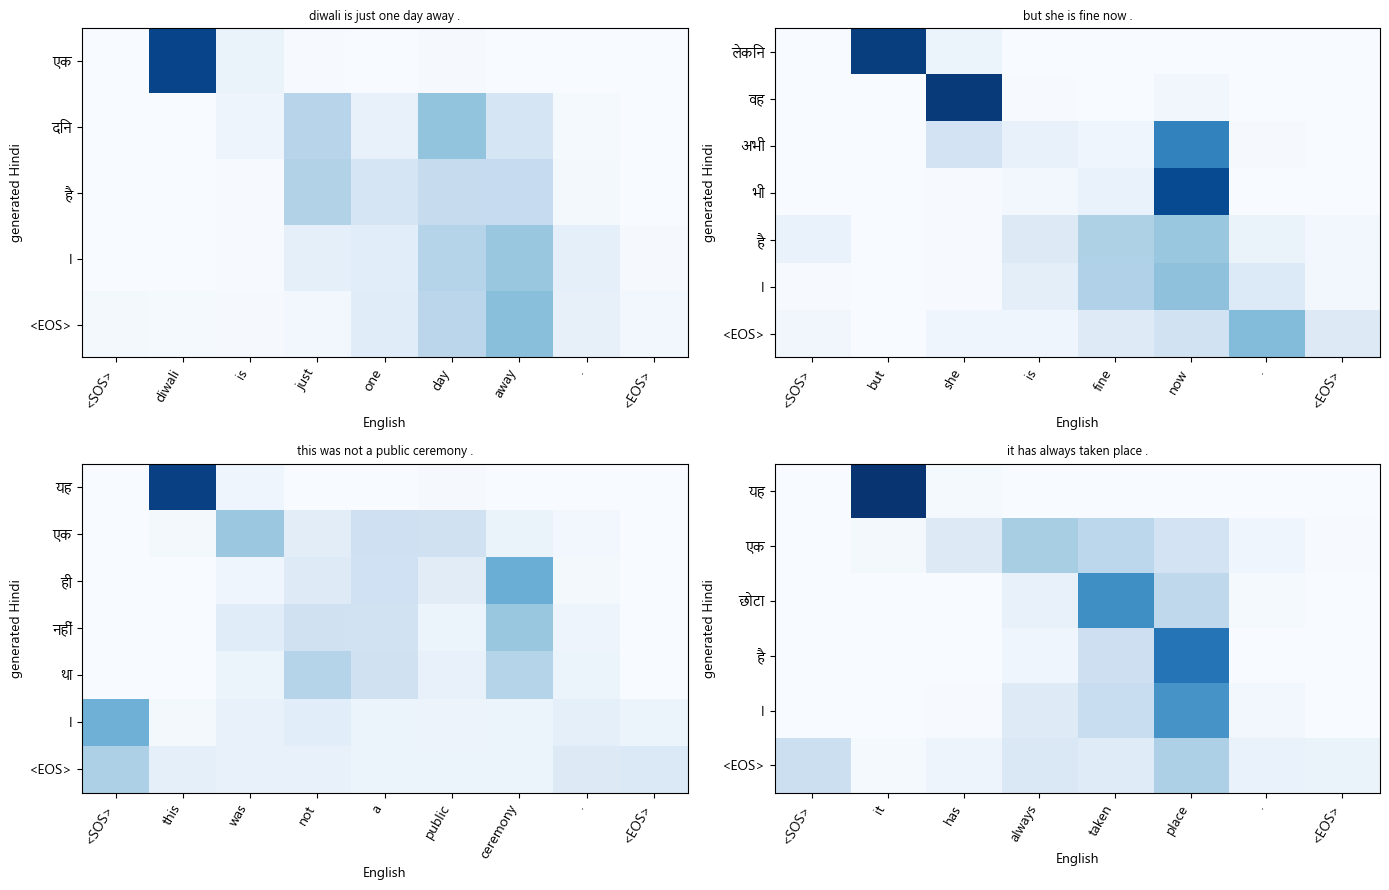

EN : diwali is just one day away .
REF: दीपावली को एक दिन शेष बचा है ।
HYP: एक दिन है ।

EN : but she is fine now .
REF: लेकिन अब वह अच्छी है ।
HYP: लेकिन वह अभी भी है ।

EN : this was not a public ceremony .
REF: यह कोई सार्वजनिक समारोह नहीं था ।
HYP: यह एक ही नहीं था ।

EN : it has always taken place .
REF: यह हमेशा होती आई है ।
HYP: यह एक छोटा है ।



In [10]:
good = sorted([i for i, (e, _) in enumerate(test) if 4 <= len(e) <= 8],
              key=lambda i: -word_overlap(hyps["attention"][i], refs[i]))[:4]
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, i in zip(axes.ravel(), good):
    plot_heatmap(test[i][0], hyps["attention"][i], alphas["attention"][i], title=" ".join(test[i][0]), ax=ax)
plt.tight_layout(); plt.savefig("results/heatmaps.png", dpi=130); plt.show()
for i in good:
    print("EN :", " ".join(test[i][0])); print("REF:", " ".join(refs[i])); print("HYP:", " ".join(hyps["attention"][i])); print()

In [11]:
move, peak, spread = attention_stats(alphas["attention"])
print(f"peak moves left to right (never goes back) : {move:.0%} of steps")
print(f"average highest attention weight           : {peak:.2f}")
print(f"steps where no word gets more than 0.5     : {spread:.0%}")
print(f"correlation between attention sharpness and translation quality: {confidence_vs_quality(alphas['attention'], hyps['attention'], refs):.2f}")

peak moves left to right (never goes back) : 77% of steps
average highest attention weight           : 0.32
steps where no word gets more than 0.5     : 86%


correlation between attention sharpness and translation quality: 0.20


**Reading the heatmaps** (`results/heatmaps.png`):

- *Which English words get high attention?* The first words of the translation look sharply at the right English word: "but" gives लेकिन, "she" gives वह, "this" and "it" give यह, "he said" gives उन्होंने कहा, and "now" gives अभी भी.
- *Relevant source word?* Yes at the start of the sentence and for connectors ("but" gives बल्कि in error case 1). Later words are weaker: in "this was not a public ceremony" the word नहीं looks at "ceremony" and "not" together, and in case 5 "यह" looks at "congress has" and "नहीं है" looks at "media questions".
- *Sequential?* Mostly at the start: the strongest word moves forward or stays in 77% of the steps. Hindi puts the verb last and English puts it in the middle, so the later steps jump around.
- *Several source words at once?* Yes, very often. In 86% of the steps no English word gets more than 0.5 and the average highest weight is 0.32, so after the first words the attention is spread over many words.
- *Incorrect attention?* In case 4 the repeated "यह है" looks at "bwelle said" instead of "not easy". In case 1 the first word "भारत" looks sharply at "asaram" (a name the model does not know) and gives the wrong word.
- Sharper attention goes with slightly better translations, but only weakly (correlation 0.20).
- In the earlier 30,000 pair run many Hindi words looked at the full stop or a comma. With more data that pattern almost disappeared (the "incorrect attention focus" rule now fires for 0.1% of the translations, before it was 11.6%).

## Part 7: error analysis

--- case 1 ---
English  : asaram has a following not only in india , but also equally in america .
Reference: आसाराम का भारत में ही नहीं , बल्कि अमेरिका में ही उतना भी प्रभुत्व है ।
Baseline : भारत में इस प्रकार की एक ऐसी हालत जो भी नहीं है ।
Attention: भारत में भी एक ही नहीं है , बल्कि एक ही में भी देखें ।
Error type: unknown/OOV word, incorrect word


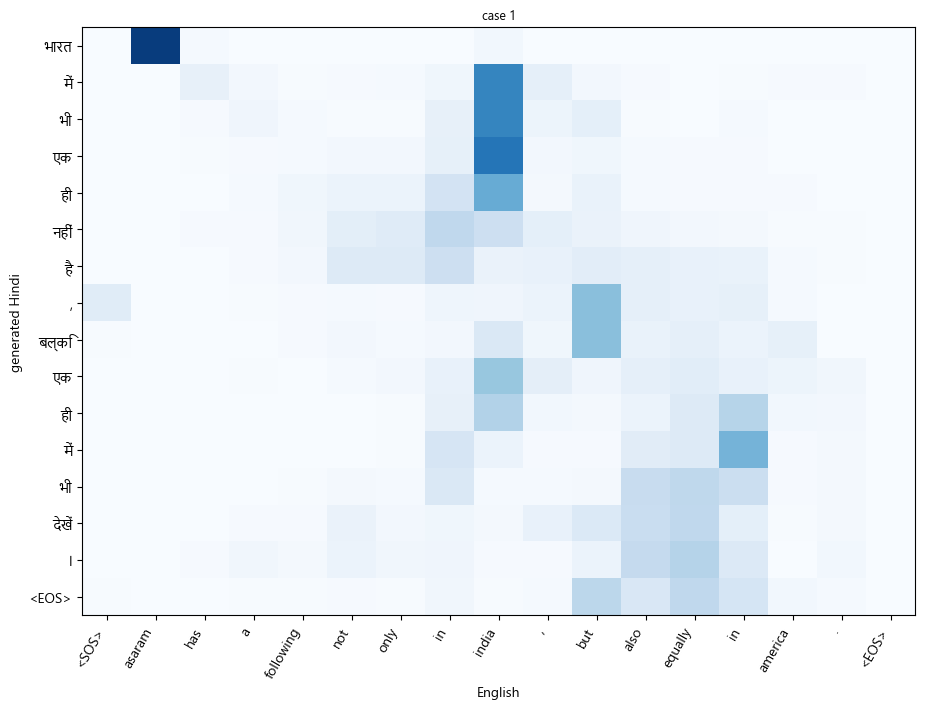

--- case 2 ---
English  : diwali is just one day away .
Reference: दीपावली को एक दिन शेष बचा है ।
Baseline : एक व्यक्ति जो कुछ भी हो ।
Attention: एक दिन है ।
Error type: missing word


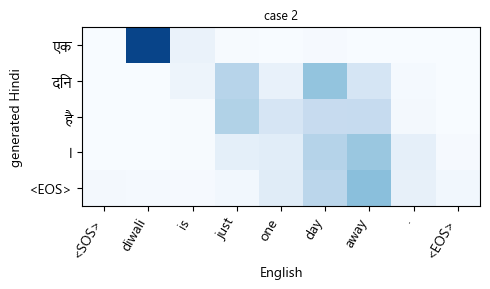

--- case 3 ---
English  : but she is fine now .
Reference: लेकिन अब वह अच्छी है ।
Baseline : लेकिन यह सच है ।
Attention: लेकिन वह अभी भी है ।
Error type: incorrect word


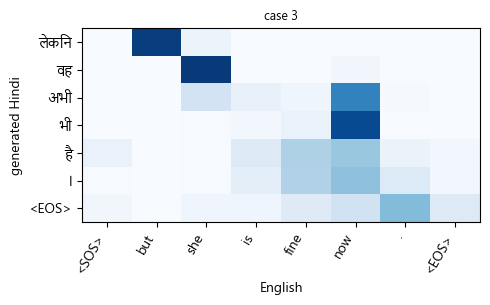

--- case 4 ---
English  : " it ' s not easy , " bwelle said .
Reference: वेल ने कहा , " यह आसान नहीं है । "
Baseline : " मैं तुम्हें नहीं है , " मैं तुम्हें नहीं है ।
Attention: " यह नहीं है , " यह है । "
Error type: unknown/OOV word, repeated word


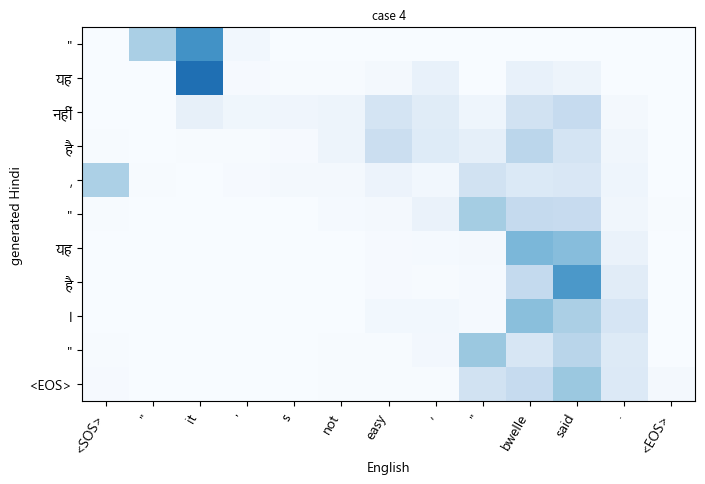

--- case 5 ---
English  : he said , " congress has become so arrogant that does not answer media questions . "
Reference: उन्होंने कहा , " कांग्रेस इतनी अहंकारी हो गई है कि वह मीडिया के सवालों का जवाब नहीं देती है । "
Baseline : उसने कहा , " ऐ मूसा ! " तुम कह रहा है , " तुम सच्चे हो , " तुम लोग गुमराही की
Attention: उन्होंने कहा , " यह आपके पास है कि यह आपके पास नहीं है ।
Error type: unknown/OOV word, missing word, long-distance dependency


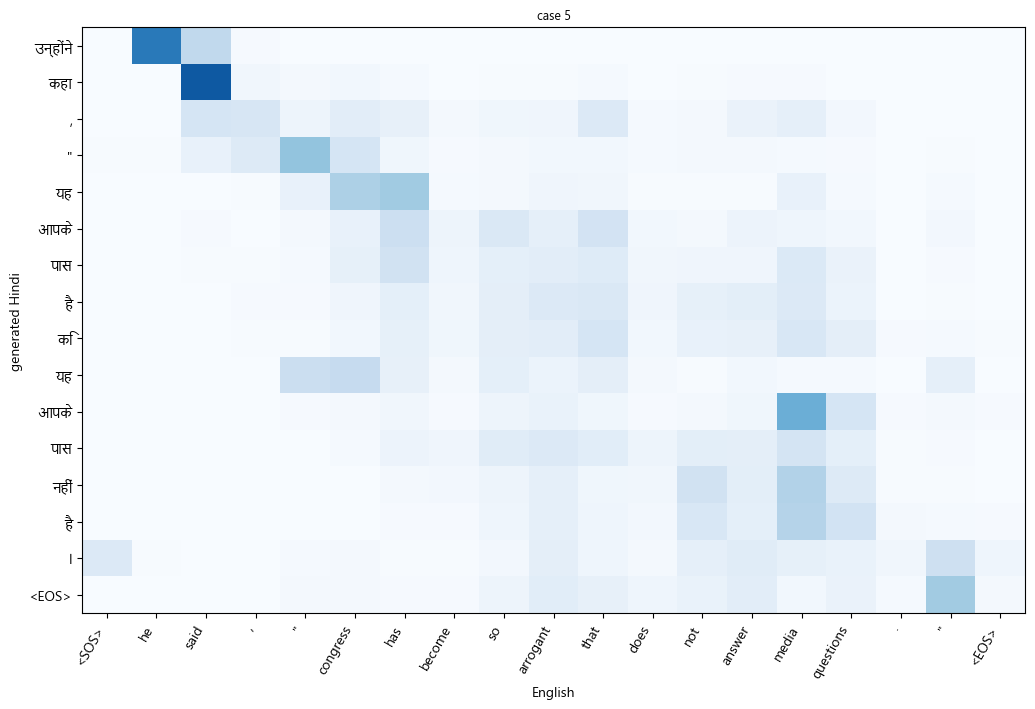

--- case 6 ---
English  : he said : " in some cases , it has reached too far inappropriately . "
Reference: उन्होंने कहा किः " कुछ मामलों में , यह अनुपयुक्त रूप से बहुत आगे चली गई है । "
Baseline : उसने कहा , " हम तो एक ही एक अनुस्मृति है , " मेरे पास लाओ था ।
Attention: उन्होंने कहा , " यह वादा कब कहा , " यह वादा है । "
Error type: unknown/OOV word, missing word, repeated word, long-distance dependency


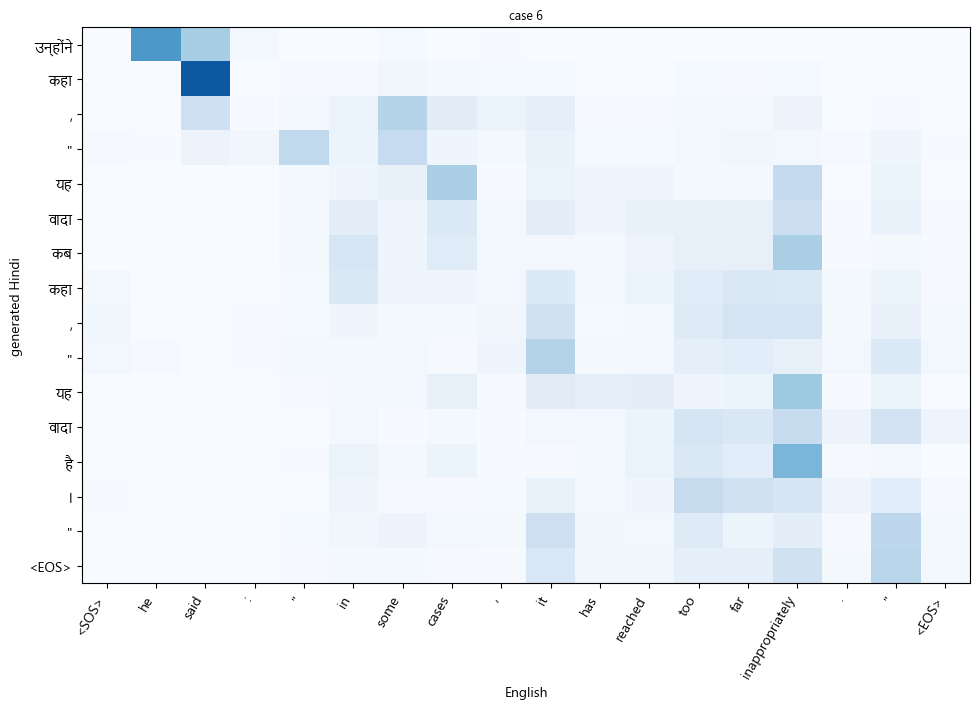

In [12]:
cases = pick_error_cases(test, hyps["baseline"], hyps["attention"], n=6)
for k, i in enumerate(cases, 1):
    labels = classify(test[i][0], refs[i], hyps["attention"][i], alphas["attention"][i], data)
    print(f"--- case {k} ---")
    print("English  :", " ".join(test[i][0]))
    print("Reference:", " ".join(refs[i]))
    print("Baseline :", " ".join(hyps["baseline"][i]))
    print("Attention:", " ".join(hyps["attention"][i]))
    print("Error type:", ", ".join(labels))
    plot_heatmap(test[i][0], hyps["attention"][i], alphas["attention"][i], title=f"case {k}", path=f"results/error_case_{k}.png")

Six wrong translations from the attention model (heatmaps are in `results/error_case_1.png` to `error_case_6.png`). The error types come from `classify()` in `analyze.py`, a simple rule based guess from the words, so read them as hints. "Incorrect attention focus" means that more than half of the generated words have their highest weight on `.`, `,`, `?`, `<SOS>` or `<EOS>`; it did not fire for any of these six.

- **Case 1** (name and connector): "asaram" is not in the vocabulary. The model looks sharply at it and says "भारत". It does look at "india" when writing "में भी" and at "but" when writing "बल्कि", so the structure "not only ... but also" is partly right, while the name is wrong and "america" is lost.
- **Case 2** (missing word): "diwali is just one day away". The first Hindi word "एक" looks sharply at "diwali", an unknown word, and the model falls back on a generic word. The reference "दीपावली ... शेष बचा" is missing.
- **Case 3** (incorrect word): "लेकिन वह अभी भी है". The alignment is clean (but gives लेकिन, she gives वह, now gives अभी भी) but "fine" (अच्छी) is never translated, so the sentence is incomplete. The baseline says "लेकिन यह सच है".
- **Case 4** (unknown word, repeated phrase): "bwelle" is unknown. After the first part, the repeated "यह है" looks at "bwelle said" and the phrase is repeated.
- **Cases 5 and 6** (long sentences): "उन्होंने कहा" looks at "he said" and is correct, but the content of the quote is wrong and the attention is spread over many words. In case 6 the repeated "यह वादा" looks at "inappropriately", a word outside the vocabulary.

**Do the heatmaps explain the errors?** Often, yes. They show that the model looked at an unknown word (cases 1, 2, 6), that the alignment was right but a word was dropped (case 3), or that the attention is diffuse on long sentences (cases 5 and 6). They do not show why the model chose a wrong word: that comes from the decoder, which falls back on frequent phrases such as "एक", "यह है" and "यह वादा" when the context is weak. So attention is a useful clue, not a full explanation.

## Part 8: performance by sentence length

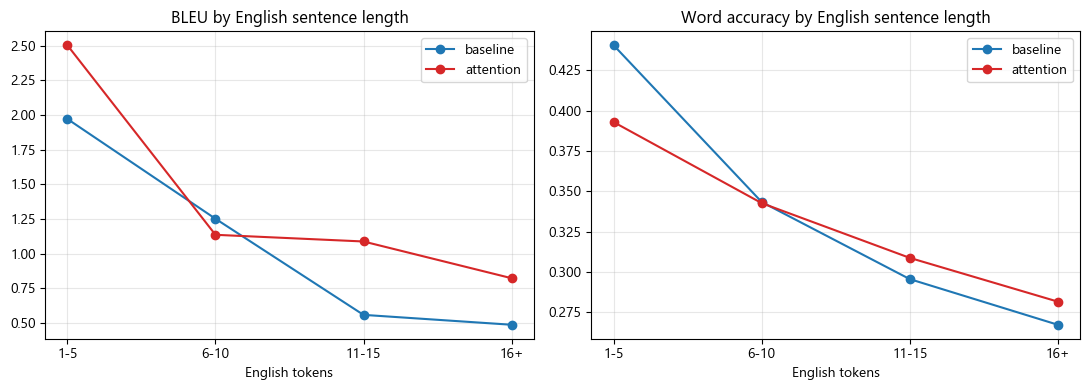

,bucket,n,baseline_bleu,baseline_acc,attention_bleu,attention_acc,bleu gain,acc gain
0,1-5,10,1.971,0.440,2.502,0.393,0.531,-0.048
1,6-10,256,1.252,0.343,1.136,0.343,-0.116,-0.001
2,11-15,455,0.559,0.296,1.088,0.309,0.529,0.013
3,16+,1002,0.488,0.267,0.823,0.282,0.335,0.014


In [13]:
rows = length_table(models, test, data, hyps)
table = pd.DataFrame(rows)
table["bleu gain"] = table["attention_bleu"] - table["baseline_bleu"]
table["acc gain"] = table["attention_acc"] - table["baseline_acc"]
plot_length(rows, "results/length.png")
table.round(3)

BLEU and word accuracy are low, so look at the direction and not the exact values. Attention is ahead on BLEU for 11-15 tokens (1.09 vs 0.56) and 16+ tokens (0.82 vs 0.49), about equal for 6-10 (1.14 vs 1.25), and ahead for 1-5 (only 10 sentences). Word accuracy tells the same story: +0.013 and +0.014 for 11-15 and 16+, and no change for 6-10. Word overlap with the reference (Part 9) is higher for attention in every group (0.207 vs 0.174, 0.220 vs 0.195, 0.208 vs 0.182, 0.199 vs 0.187). So attention does not hurt on short sentences and helps clearly from 11 tokens up. The gain does not keep growing with length: both models are weak on the longest group (16+), where attention's overlap gain is the smallest (+0.012).

## Part 9: error types, baseline vs attention

In [14]:
wrong = [i for i in range(len(test)) if hyps["attention"][i] != refs[i]]
rows = {}
for name in models:
    counts = Counter()
    for i in range(len(test)):
        if hyps[name][i] != refs[i]:
            counts.update(classify(test[i][0], refs[i], hyps[name][i], alphas[name][i], data))
    n_wrong = sum(hyps[name][i] != refs[i] for i in range(len(test)))
    rows[name] = {label: c / n_wrong for label, c in counts.items()}
    print(name, ":", n_wrong, "of", len(test), "test sentences differ from the reference")
pd.DataFrame(rows).fillna(0).round(3).sort_values("baseline", ascending=False)

baseline : 1723 of 1723 test sentences differ from the reference
attention : 1723 of 1723 test sentences differ from the reference


,baseline,attention
unknown/OOV word,0.831,0.831
long-distance dependency,0.582,0.582
missing word,0.430,0.382
repeated word,0.371,0.463
extra word,0.295,0.343
incorrect word,0.273,0.273
incorrect attention focus,0.000,0.001


In [15]:
overlap = {name: np.array([word_overlap(hyps[name][i], refs[i]) for i in range(len(test))]) for name in models}
diff = overlap["attention"] - overlap["baseline"]
print("average word overlap with the reference (F1):", {k: round(v.mean(), 3) for k, v in overlap.items()})
print(f"attention better on {(diff > 0).sum()} sentences, worse on {(diff < 0).sum()}, same on {(diff == 0).sum()}")
print(f"mean difference {diff.mean():.4f}, standard error {diff.std() / np.sqrt(len(diff)):.4f}")
print()
for name, lo, hi in BUCKETS:
    idx = [i for i, (e, _) in enumerate(test) if lo <= len(e) <= hi]
    print(f"{name:>5} tokens: overlap baseline {overlap['baseline'][idx].mean():.3f}   attention {overlap['attention'][idx].mean():.3f}")
print()
unk = {name: np.mean([w == "<UNK>" for h in hyps_unk[name] for w in h]) for name in models}
print("share of generated words that are <UNK> when it is allowed:", {k: round(v, 3) for k, v in unk.items()})
print("share of reference words outside the Hindi vocabulary:", round(np.mean([w not in data["hi_stoi"] for r in refs for w in r]), 3))

average word overlap with the reference (F1): {'baseline': 0.187, 'attention': 0.205}
attention better on 926 sentences, worse on 718, same on 79
mean difference 0.0178, standard error 0.0024

  1-5 tokens: overlap baseline 0.174   attention 0.207
 6-10 tokens: overlap baseline 0.195   attention 0.220
11-15 tokens: overlap baseline 0.182   attention 0.208
  16+ tokens: overlap baseline 0.187   attention 0.199



share of generated words that are <UNK> when it is allowed: {'baseline': 0.568, 'attention': 0.674}
share of reference words outside the Hindi vocabulary: 0.12


## Final comparison

**How does attention compare with the baseline?** Better, but both models are weak. Validation loss 4.654 vs 4.760, validation word accuracy 0.302 vs 0.289, test BLEU 0.92 vs 0.60 and word overlap F1 0.205 vs 0.187. The paired comparison says attention is better on 926 test sentences, worse on 718 and equal on 79, with a mean difference of 0.0178 and a standard error of 0.0024, so the gain is clear in this run (about 7 standard errors) but small in size. It comes from one training run per model. In the earlier 30,000 pair run the gain was half as big (0.0095), so more training data made the benefit of attention larger.

**Short or long sentences?** Attention helps for every group by word overlap, and clearly on BLEU and accuracy from 11 tokens up. The gain is not biggest for the longest sentences: those are hard for both models.

**Which errors are reduced?** Missing words go down (43.0% to 38.2% of the translations). Repeated words (37.1% to 46.3%) and extra words (29.5% to 34.3%) go up, and incorrect words stay at 27.3%. The attention model writes longer outputs, and not all the added words are right. Unknown words (83%) and long sentences (58%) are properties of the test data and are the same for both models.

**What do the heatmaps show?** The first words are aligned correctly, then attention spreads out over many words. Good alignments appear for connectors and speech verbs ("but" gives बल्कि, "said" gives कहा). Sharp attention on an unknown word leads to a generic wrong word.

**Are high attention weights always linked to correct translations?** No. In case 3 the alignment is clean but a word is dropped, and in case 1 the model looks sharply at an unknown name and gives the wrong word. Over all sentences, sharper attention goes with better translations only weakly (correlation 0.20).

**Can attention be used as an explanation?** As a partial one. It helps to find where a translation went wrong (looking at an unknown word, spreading out on long sentences), but it cannot say why a word was chosen, and sharp attention is not proof of a correct translation.

**Limitations.** Only 50,000 training pairs, 8 epochs and one run (seed) per model; word level vocabulary with 10,000 words (about 10% of Hindi training words unknown); greedy decoding without beam search; `<UNK>` banned at decoding; a small dev set (430 sentences) and only 10 test sentences in the 1-5 group; IIT Bombay data is noisy; error types are rule based guesses; BLEU is below 1 for both models, so these are translations of common phrases and not good translations. Subword tokens, much more data, more epochs and beam search would raise the absolute quality.